In [1]:
import os
import numpy as np
import anndata as ad
import scanpy as sc
import CAST
import warnings
warnings.filterwarnings("ignore")
# work_dir = '$demo_path' #### input the demo path

In [ ]:
import pandas as pd
refAD = sc.read_h5ad("ref_input.h5ad")
queryAD = sc.read_h5ad("query_input.h5ad")



AnnData object with n_obs × n_vars = 3184 × 67
    obs: 'spot_x', 'spot_y', 'cell_count', 'Smooth muscle cells_percentage', 'Fibroblast_percentage', 'Atrial cardiomyocytes_percentage', 'Cardiomyocytes_percentage', 'Endothelium_percentage', 'Epicardium_percentage', 'Schwan progenitors_percentage', 'Ventricular cardiomyocytes_percentage', 'Cell_Num', 'New_X', 'New_Y', 'CellType'
    obsm: 'X_spatial', 'spatial'

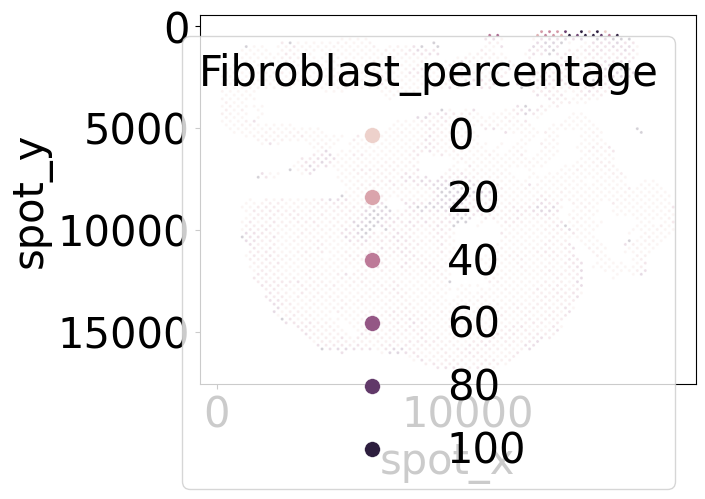

In [16]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.scatterplot(x='spot_x', y='spot_y',hue='Fibroblast_percentage', s=5,data=queryAD.obs)
plt.gca().invert_yaxis()


Constructing delaunay graphs for 2 samples...
Training on cuda:0...


Loss: -343.719 step time=0.080s: 100%|██████████| 400/400 [00:30<00:00, 13.33it/s]


Finished.
The embedding, log, model files were saved to heart_output


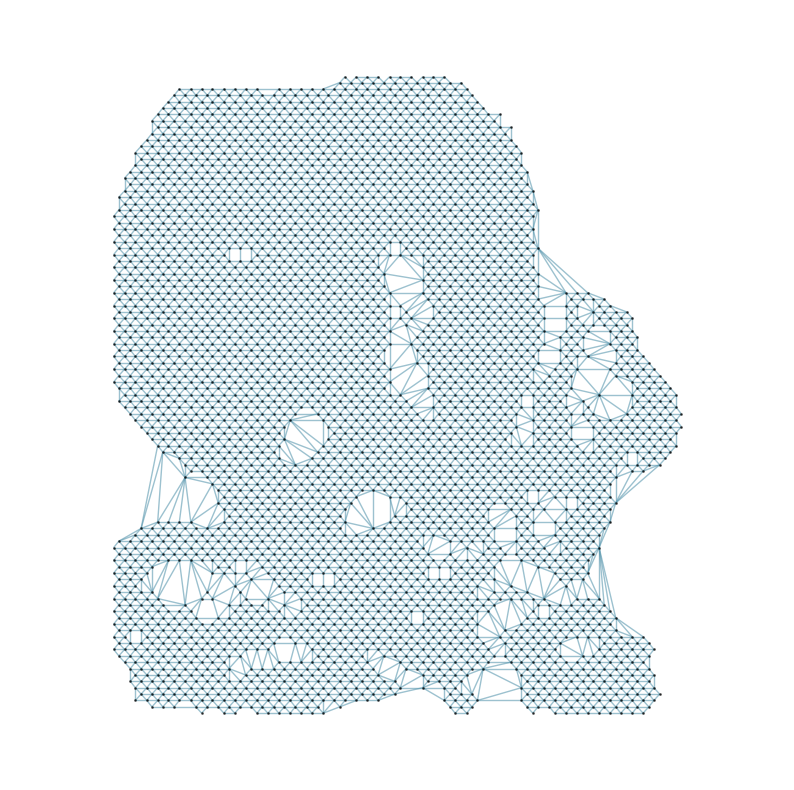

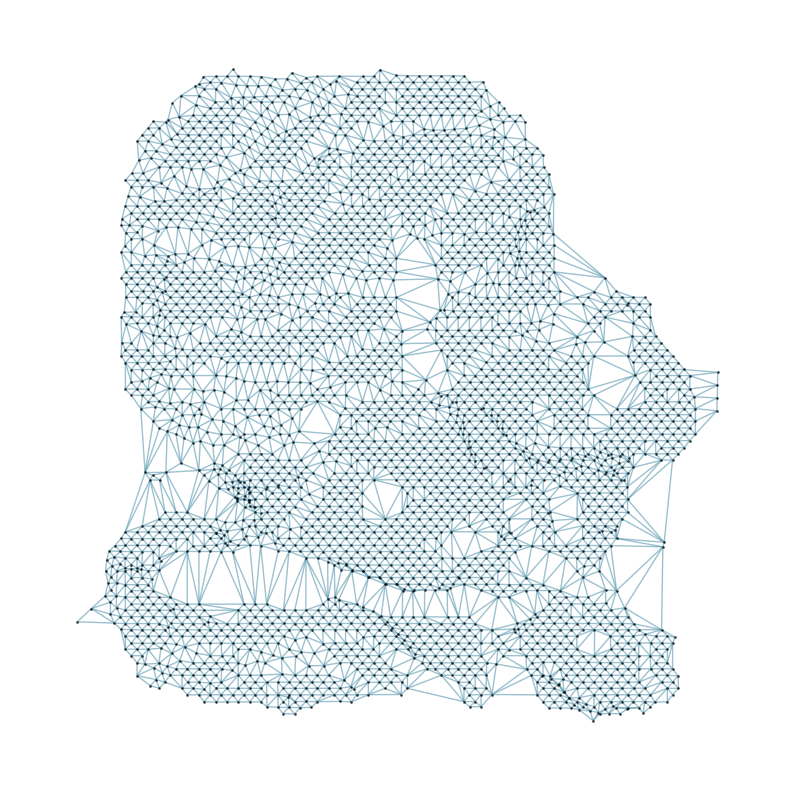

In [17]:
ref_matrix= sc.pp.normalize_total(refAD, target_sum=1e2, inplace=False)['X']
query_matrix = sc.pp.normalize_total(queryAD,target_sum=1e2, inplace=False)['X']
samples = ['ref','query']

output_path = f'heart_output'
os.makedirs(output_path, exist_ok=True)

coords_raw = {'ref': np.array(refAD.obs[['New_X','New_Y']]),'query': np.array(queryAD.obs[['New_X','New_Y']])}
exp_dict = {'ref': ref_matrix,'query': query_matrix}

embed_dict = CAST.CAST_MARK(coords_raw,exp_dict,output_path)


In [18]:
graph_list = ['query','ref'] # [query_sample, reference_sample]
dataset = 'query'


Loss: 194.508: 100%|██████████| 500/500 [00:05<00:00, 88.78it/s]
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not

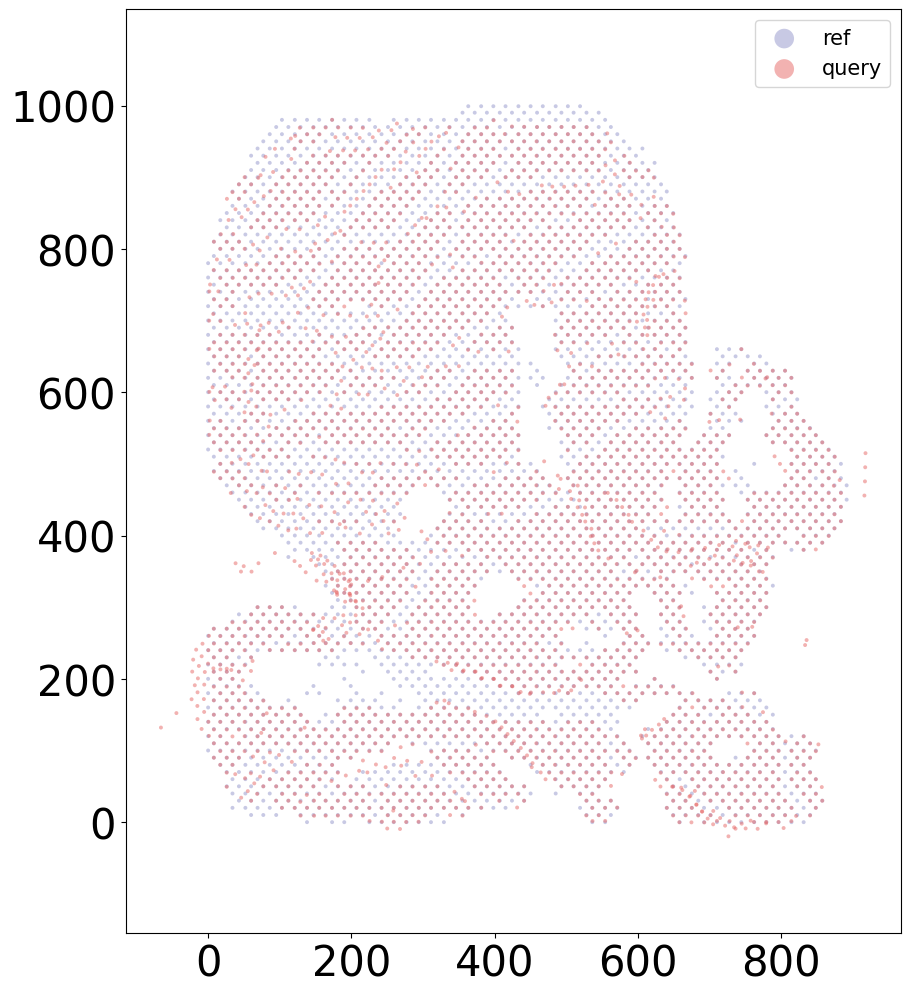

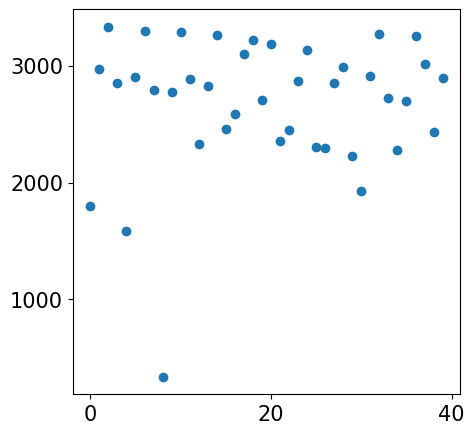

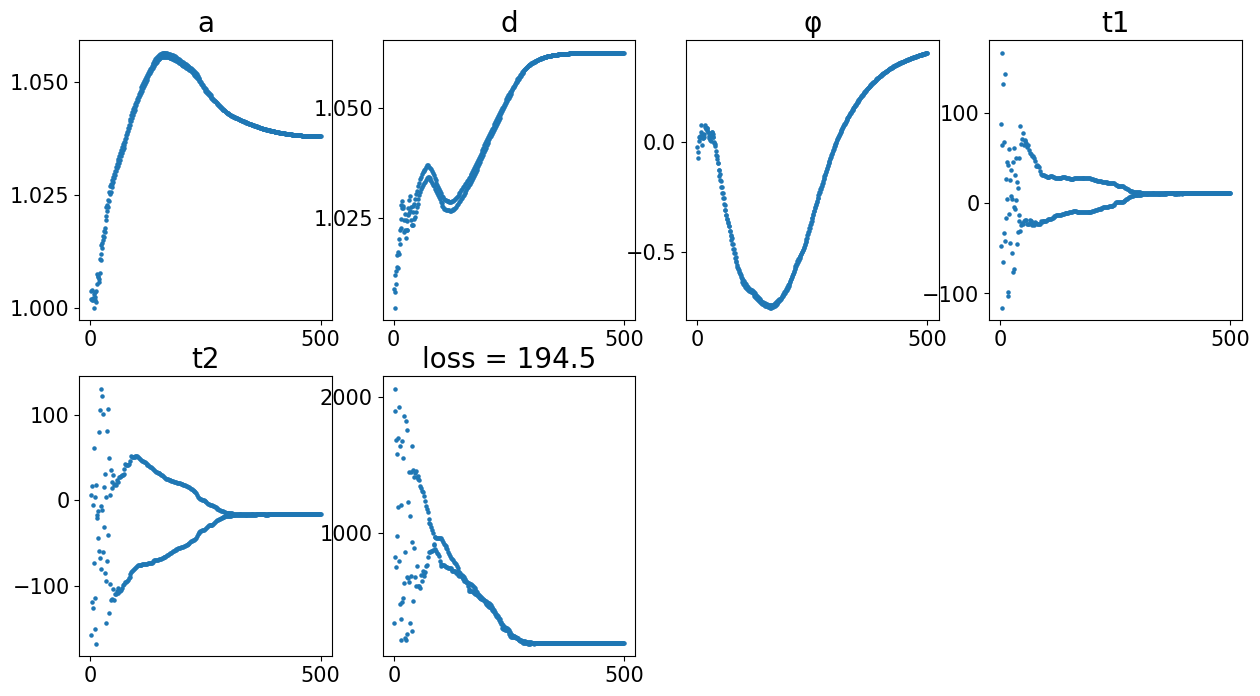

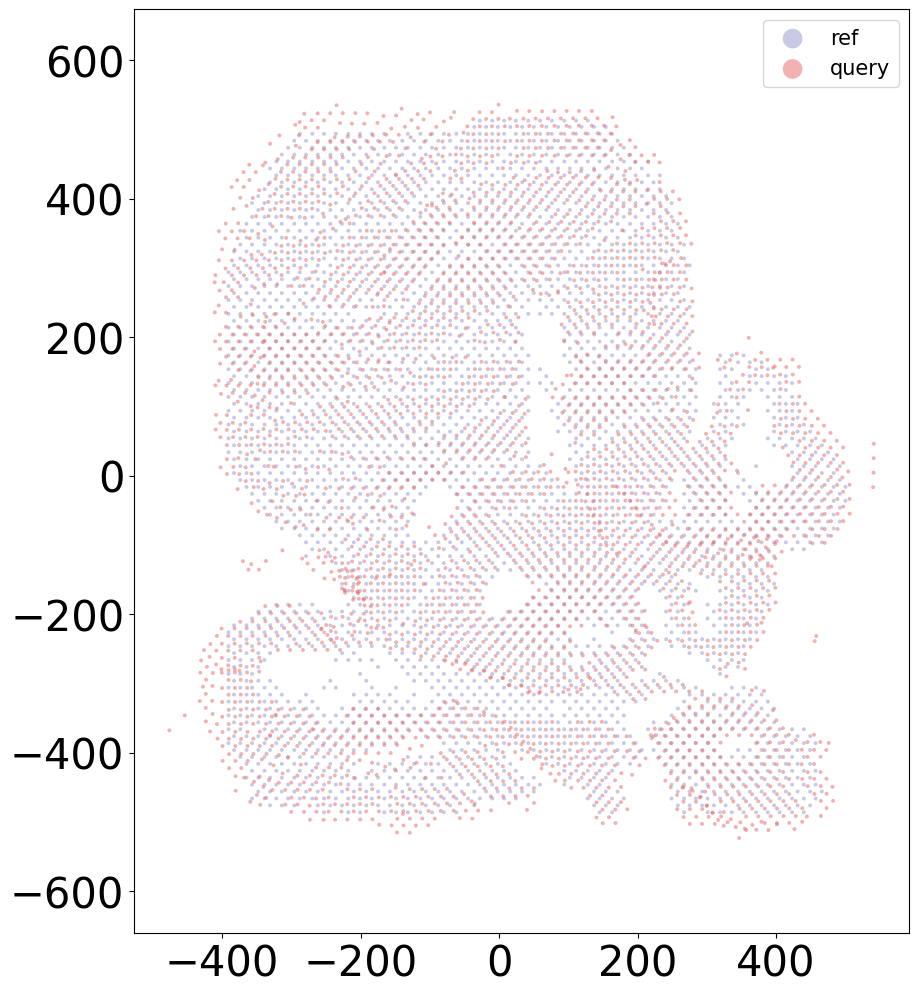

findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.


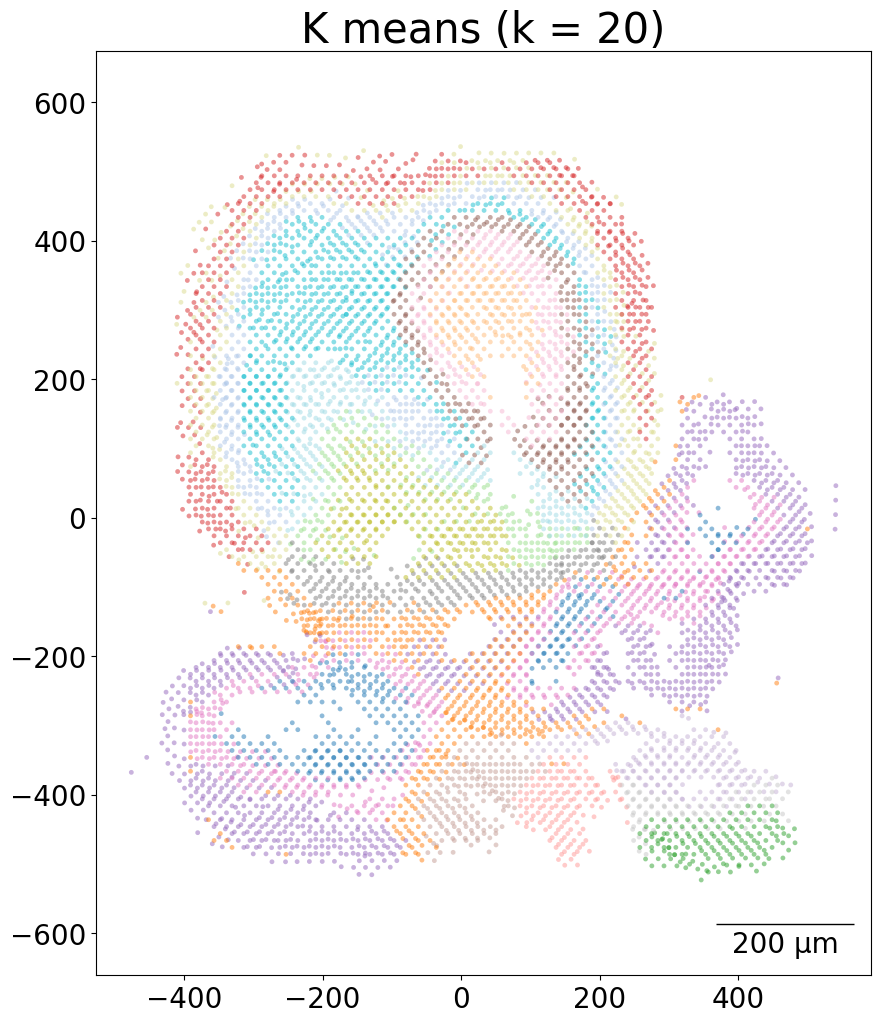

findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.


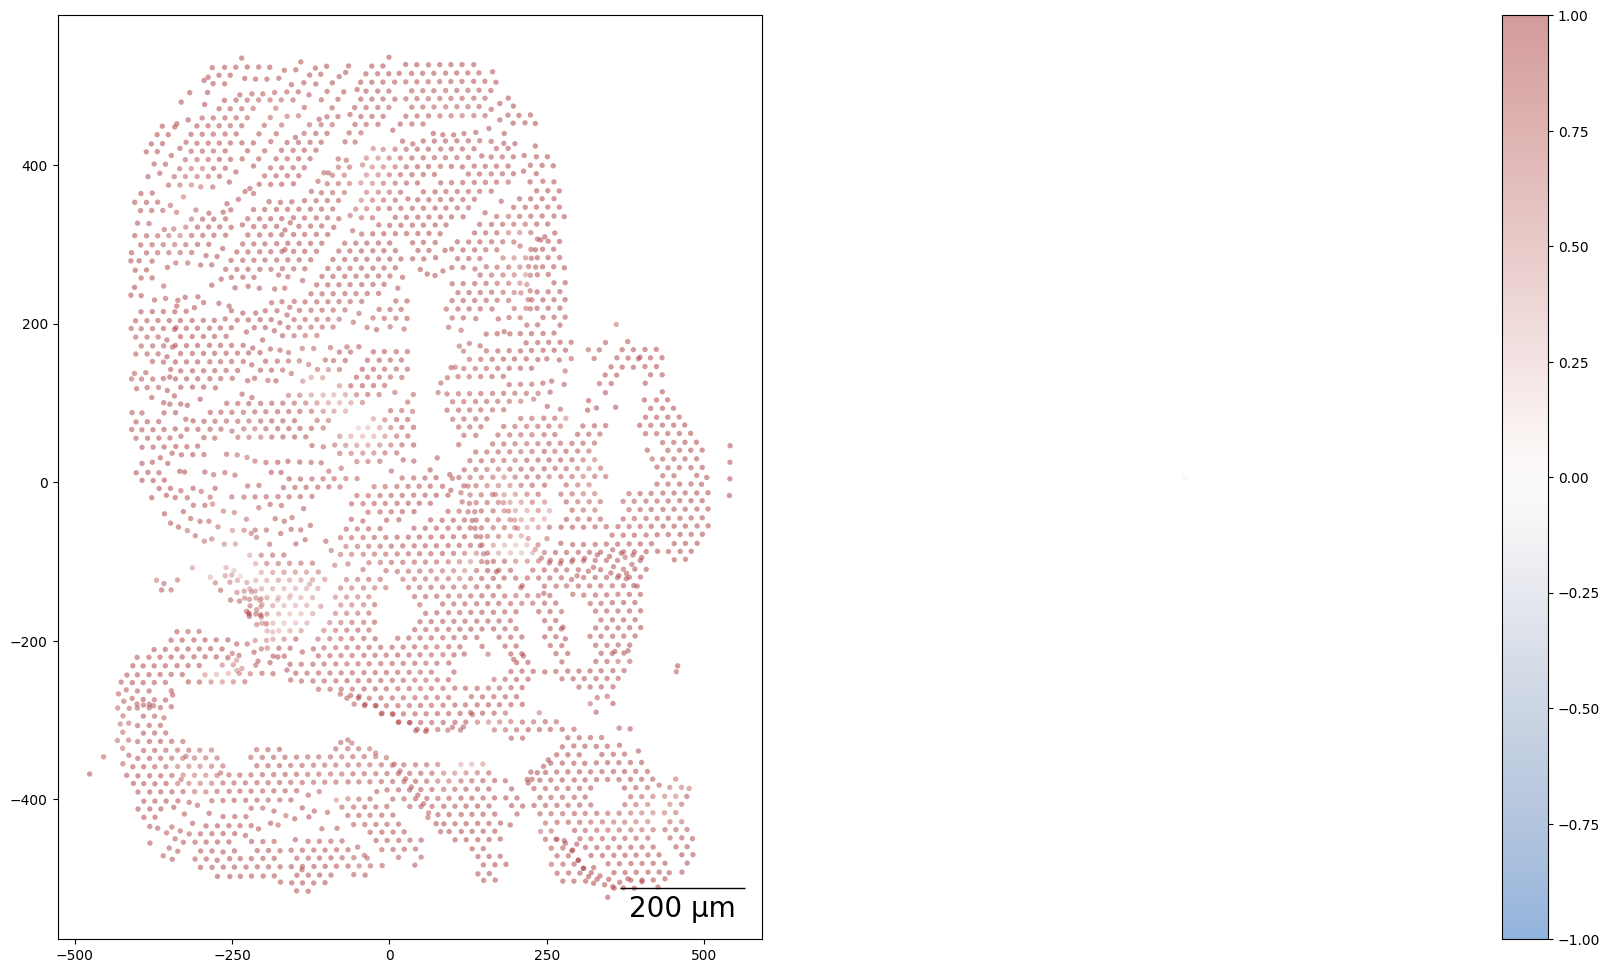

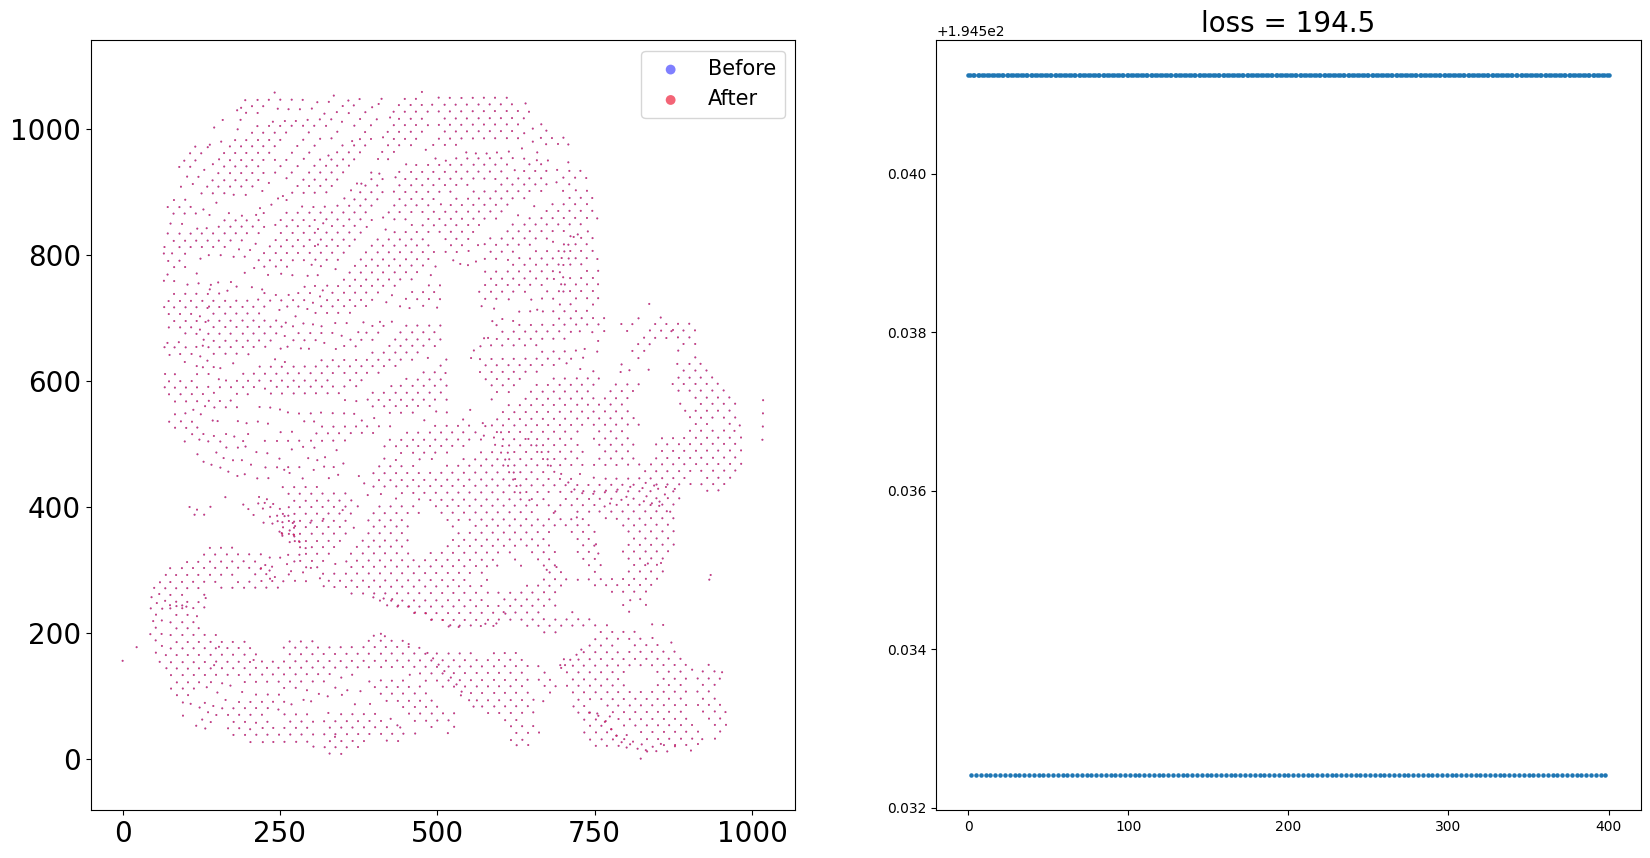

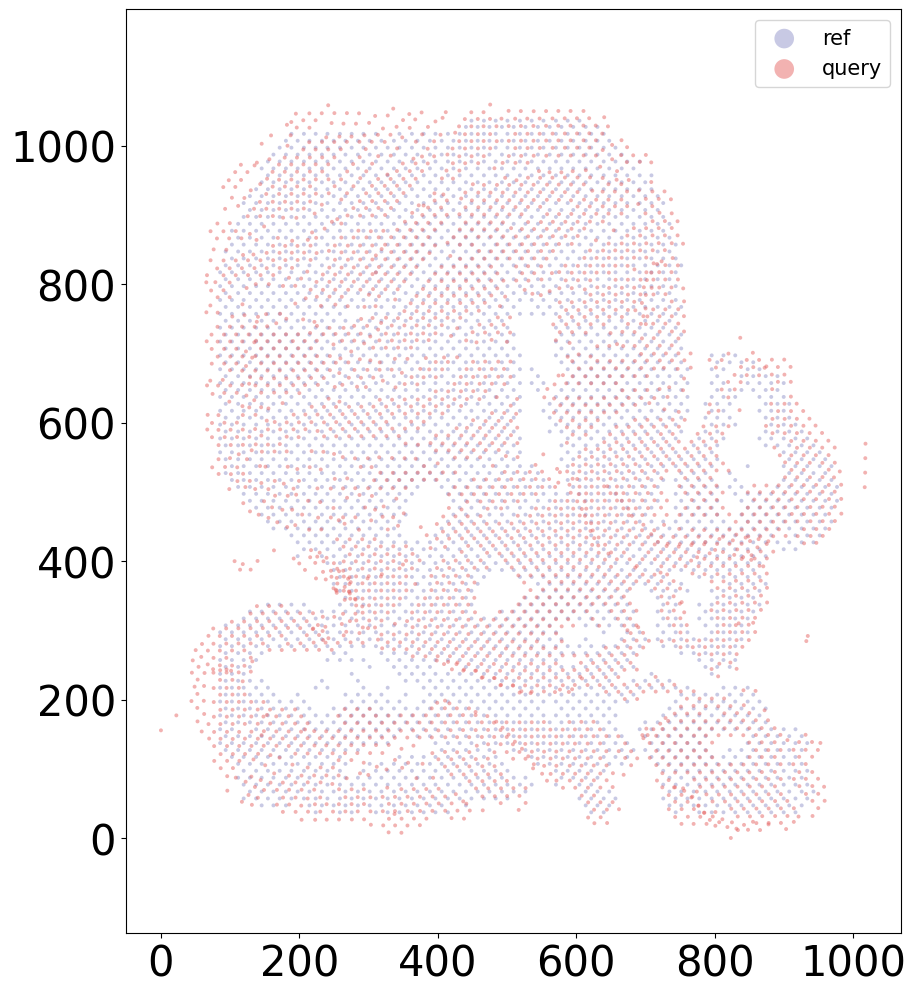

findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.


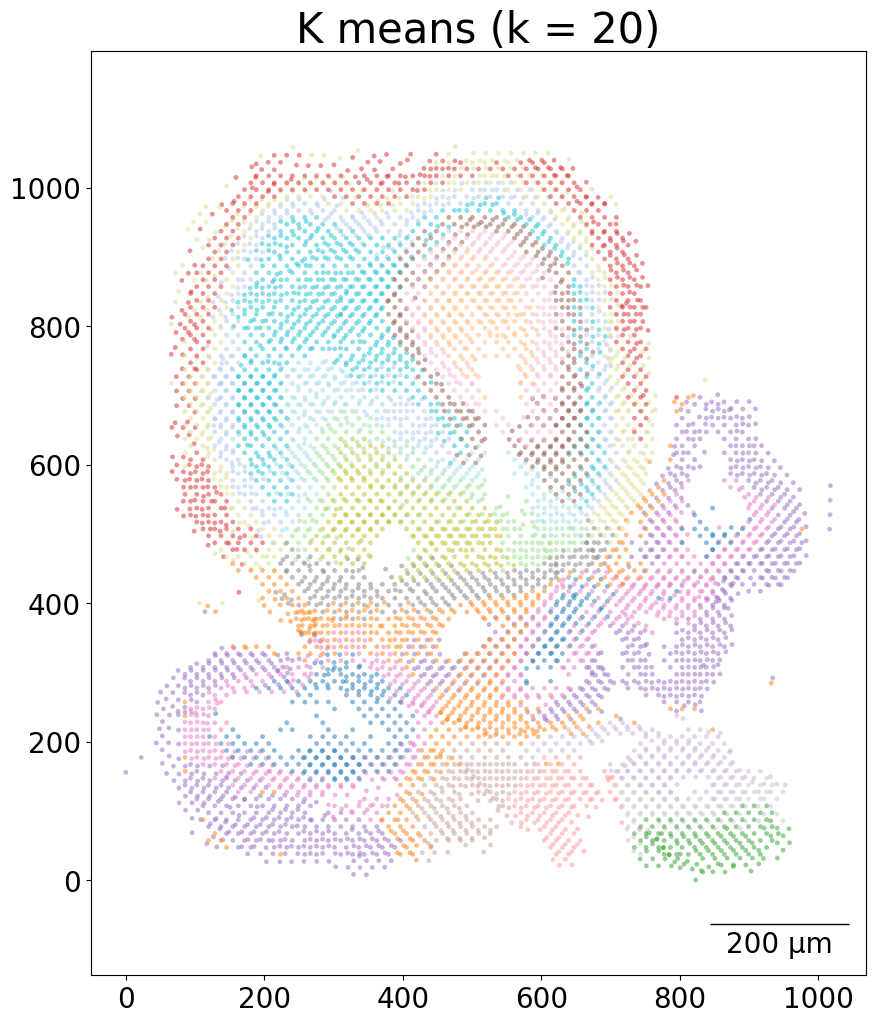

findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.


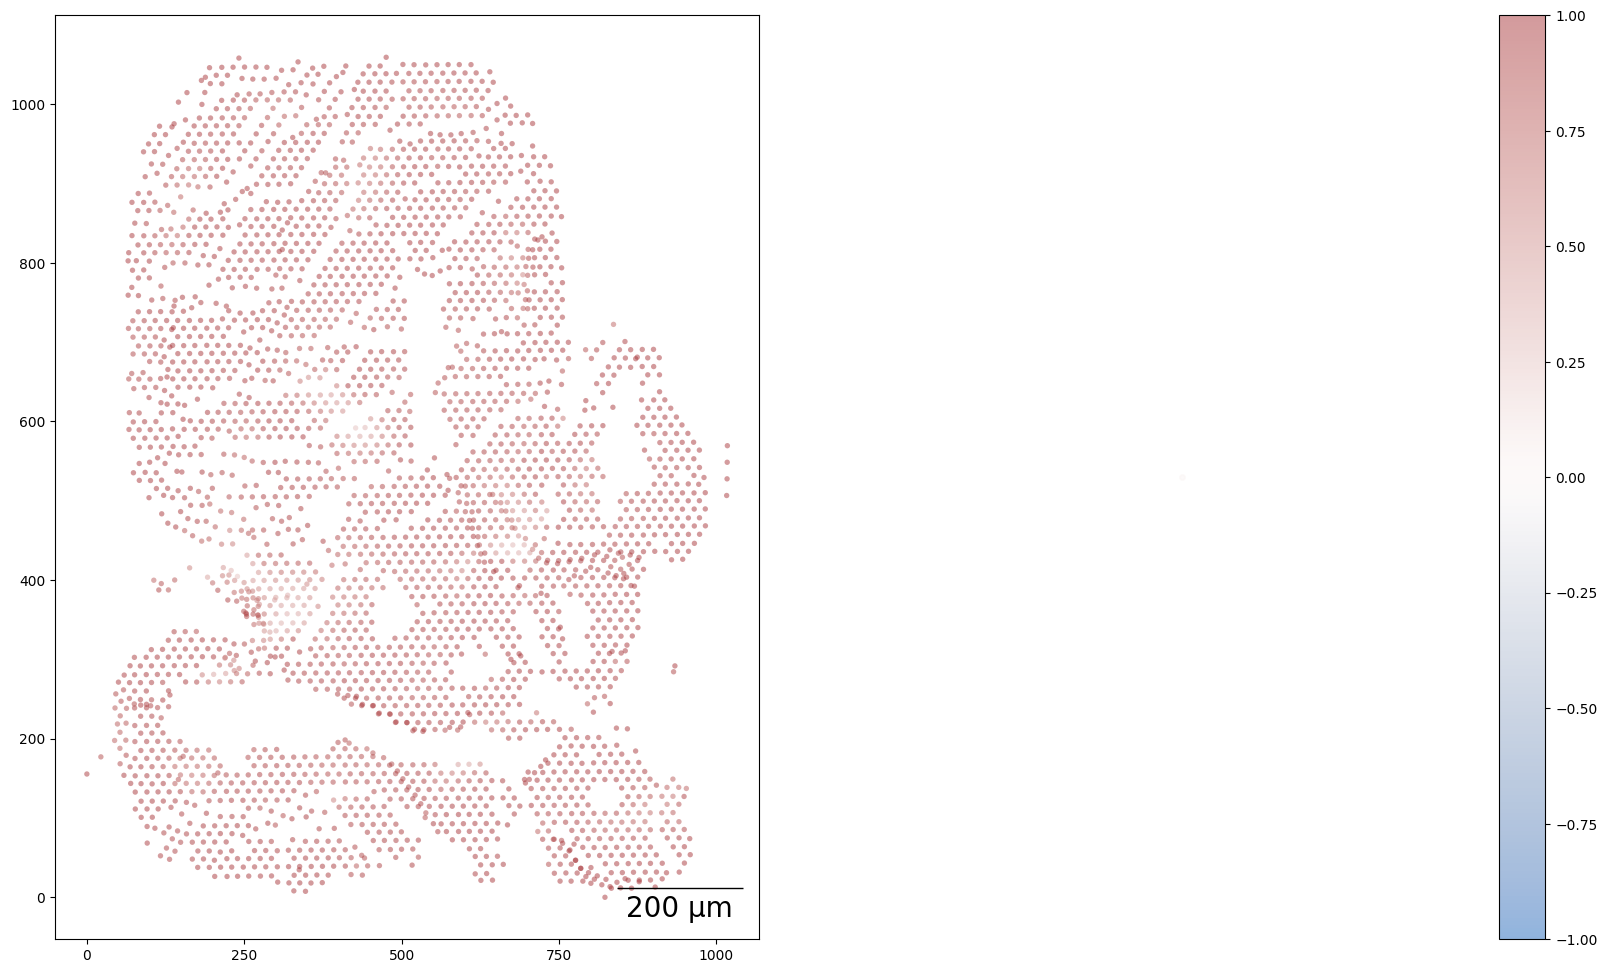

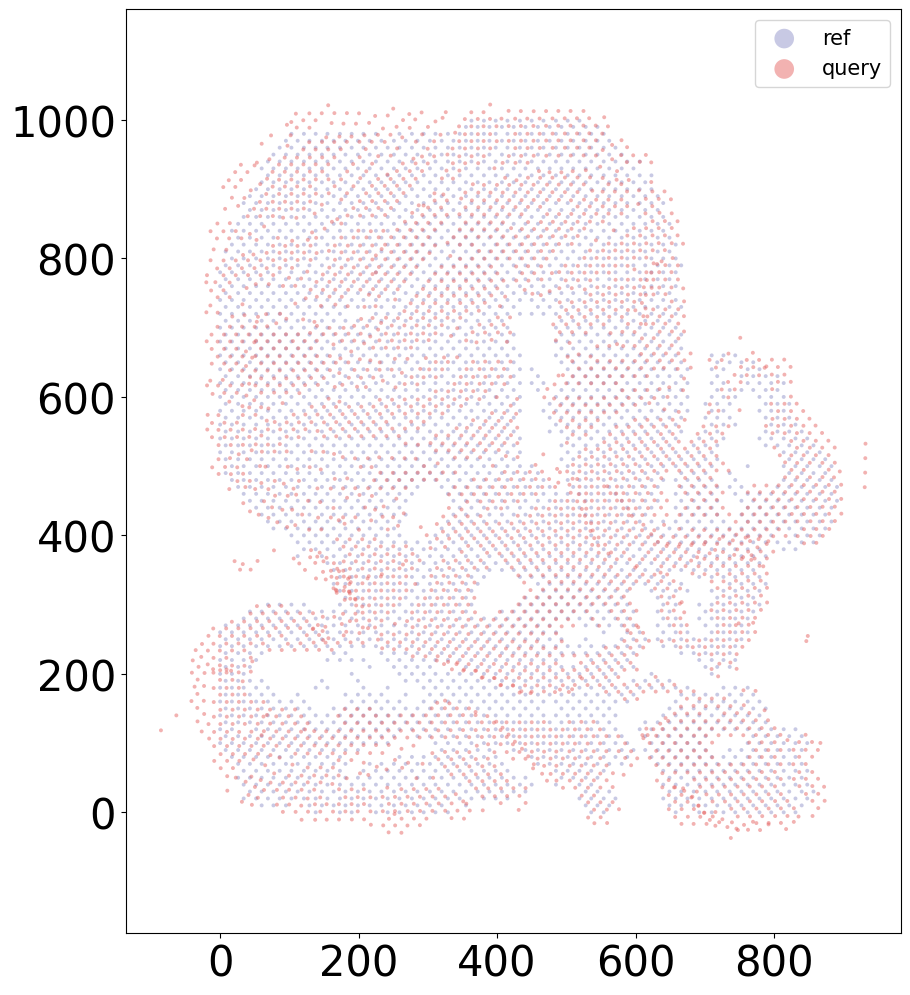

In [19]:
import CAST
import os, torch
import warnings
warnings.filterwarnings("ignore")
params_dist = CAST.reg_params(dataname = 'query',
                            gpu = 0 if torch.cuda.is_available() else -1, 
                            diff_step = 5,
                            #### Affine parameters
                            iterations=500,
                            dist_penalty1=0,
                            bleeding=250,
                            d_list = [3,2,1,1/2,1/3],
                            attention_params = [None,3,1,0], 
                            #### FFD parameters    
                            dist_penalty2 = [0],
                            alpha_basis_bs = [0, 250, 500],
                            meshsize = [8, 16, 32],
                            iterations_bs = [400],
                            attention_params_bs = [[None,3,1,0]],
                            mesh_weight = [None])
params_dist.alpha_basis = torch.Tensor([1/1000,1/1000,1/50,5,5]).reshape(5,1).to(params_dist.device)
coords_final = CAST.CAST_STACK(coords_raw,embed_dict,output_path,graph_list,params_dist)

In [20]:
coords_final

{'query': tensor([[ 666.3362,  -16.6986],
         [ 683.8700,  -16.7127],
         [ 702.5271,  -16.7013],
         ...,
         [ 488.4742, 1012.9982],
         [ 506.1725, 1013.0061],
         [ 524.8124, 1012.9708]]),
 'ref': array([[138.,   0.],
        [173.,   0.],
        [190.,   0.],
        ...,
        [485., 999.],
        [502., 999.],
        [519., 999.]])}

In [21]:
coords_final['ref'][:,0].shape

(3801,)

In [22]:
refAD.obs['CAST_X'] = coords_final['ref'][:,0]
refAD.obs['CAST_Y'] = coords_final['ref'][:,1]

queryAD.obs['CAST_X'] = coords_final['query'][:,0]
queryAD.obs['CAST_Y'] = coords_final['query'][:,1]




In [29]:
refAD.obs[['New_X','New_Y','CAST_X','CAST_Y']].head()
refAD.obsm['X_CAST_spatial'] = refAD.obs[['CAST_X','CAST_Y']]
refAD.write_h5ad('ref_CAST.h5ad')

In [24]:
queryAD.obs[['New_X','New_Y','CAST_X','CAST_Y']]

,New_X,New_Y,CAST_X,CAST_Y
0,657.516956,-0.133918,666.336182,-16.698635
1,674.407621,-0.263716,683.869995,-16.712734
2,692.380183,-0.377012,702.527100,-16.701321
3,704.671579,-2.997449,715.305481,-19.395596
4,726.064387,-19.761782,737.637146,-37.051662
...,...,...,...,...
3179,458.896835,969.977380,452.886505,1012.634766
3180,476.132349,970.059007,470.775970,1012.846924
3181,493.182212,970.083014,488.474152,1012.998169
3182,510.231735,969.973623,506.172516,1013.006104


In [25]:
queryAD.obsm['X_CAST_spatial'] = queryAD.obs[['CAST_X','CAST_Y']]

AnnData object with n_obs × n_vars = 3801 × 67
    obs: 'spot_x', 'spot_y', 'cell_count', 'Endothelium_percentage', 'Atrial cardiomyocytes_percentage', 'Cardiomyocytes_percentage', 'Epicardium_percentage', 'Fibroblast_percentage', 'Schwan progenitors_percentage', 'Smooth muscle cells_percentage', 'Ventricular cardiomyocytes_percentage', 'Cell_Num', 'New_X', 'New_Y', 'CellType', 'CAST_X', 'CAST_Y'
    obsm: 'X_spatial', 'spatial'

In [27]:
queryAD

AnnData object with n_obs × n_vars = 3184 × 67
    obs: 'spot_x', 'spot_y', 'cell_count', 'Smooth muscle cells_percentage', 'Fibroblast_percentage', 'Atrial cardiomyocytes_percentage', 'Cardiomyocytes_percentage', 'Endothelium_percentage', 'Epicardium_percentage', 'Schwan progenitors_percentage', 'Ventricular cardiomyocytes_percentage', 'Cell_Num', 'New_X', 'New_Y', 'CellType', 'CAST_X', 'CAST_Y'
    obsm: 'X_spatial', 'spatial', 'X_CAST_spatial'

In [26]:
queryAD.write_h5ad('query_CAST.h5ad')

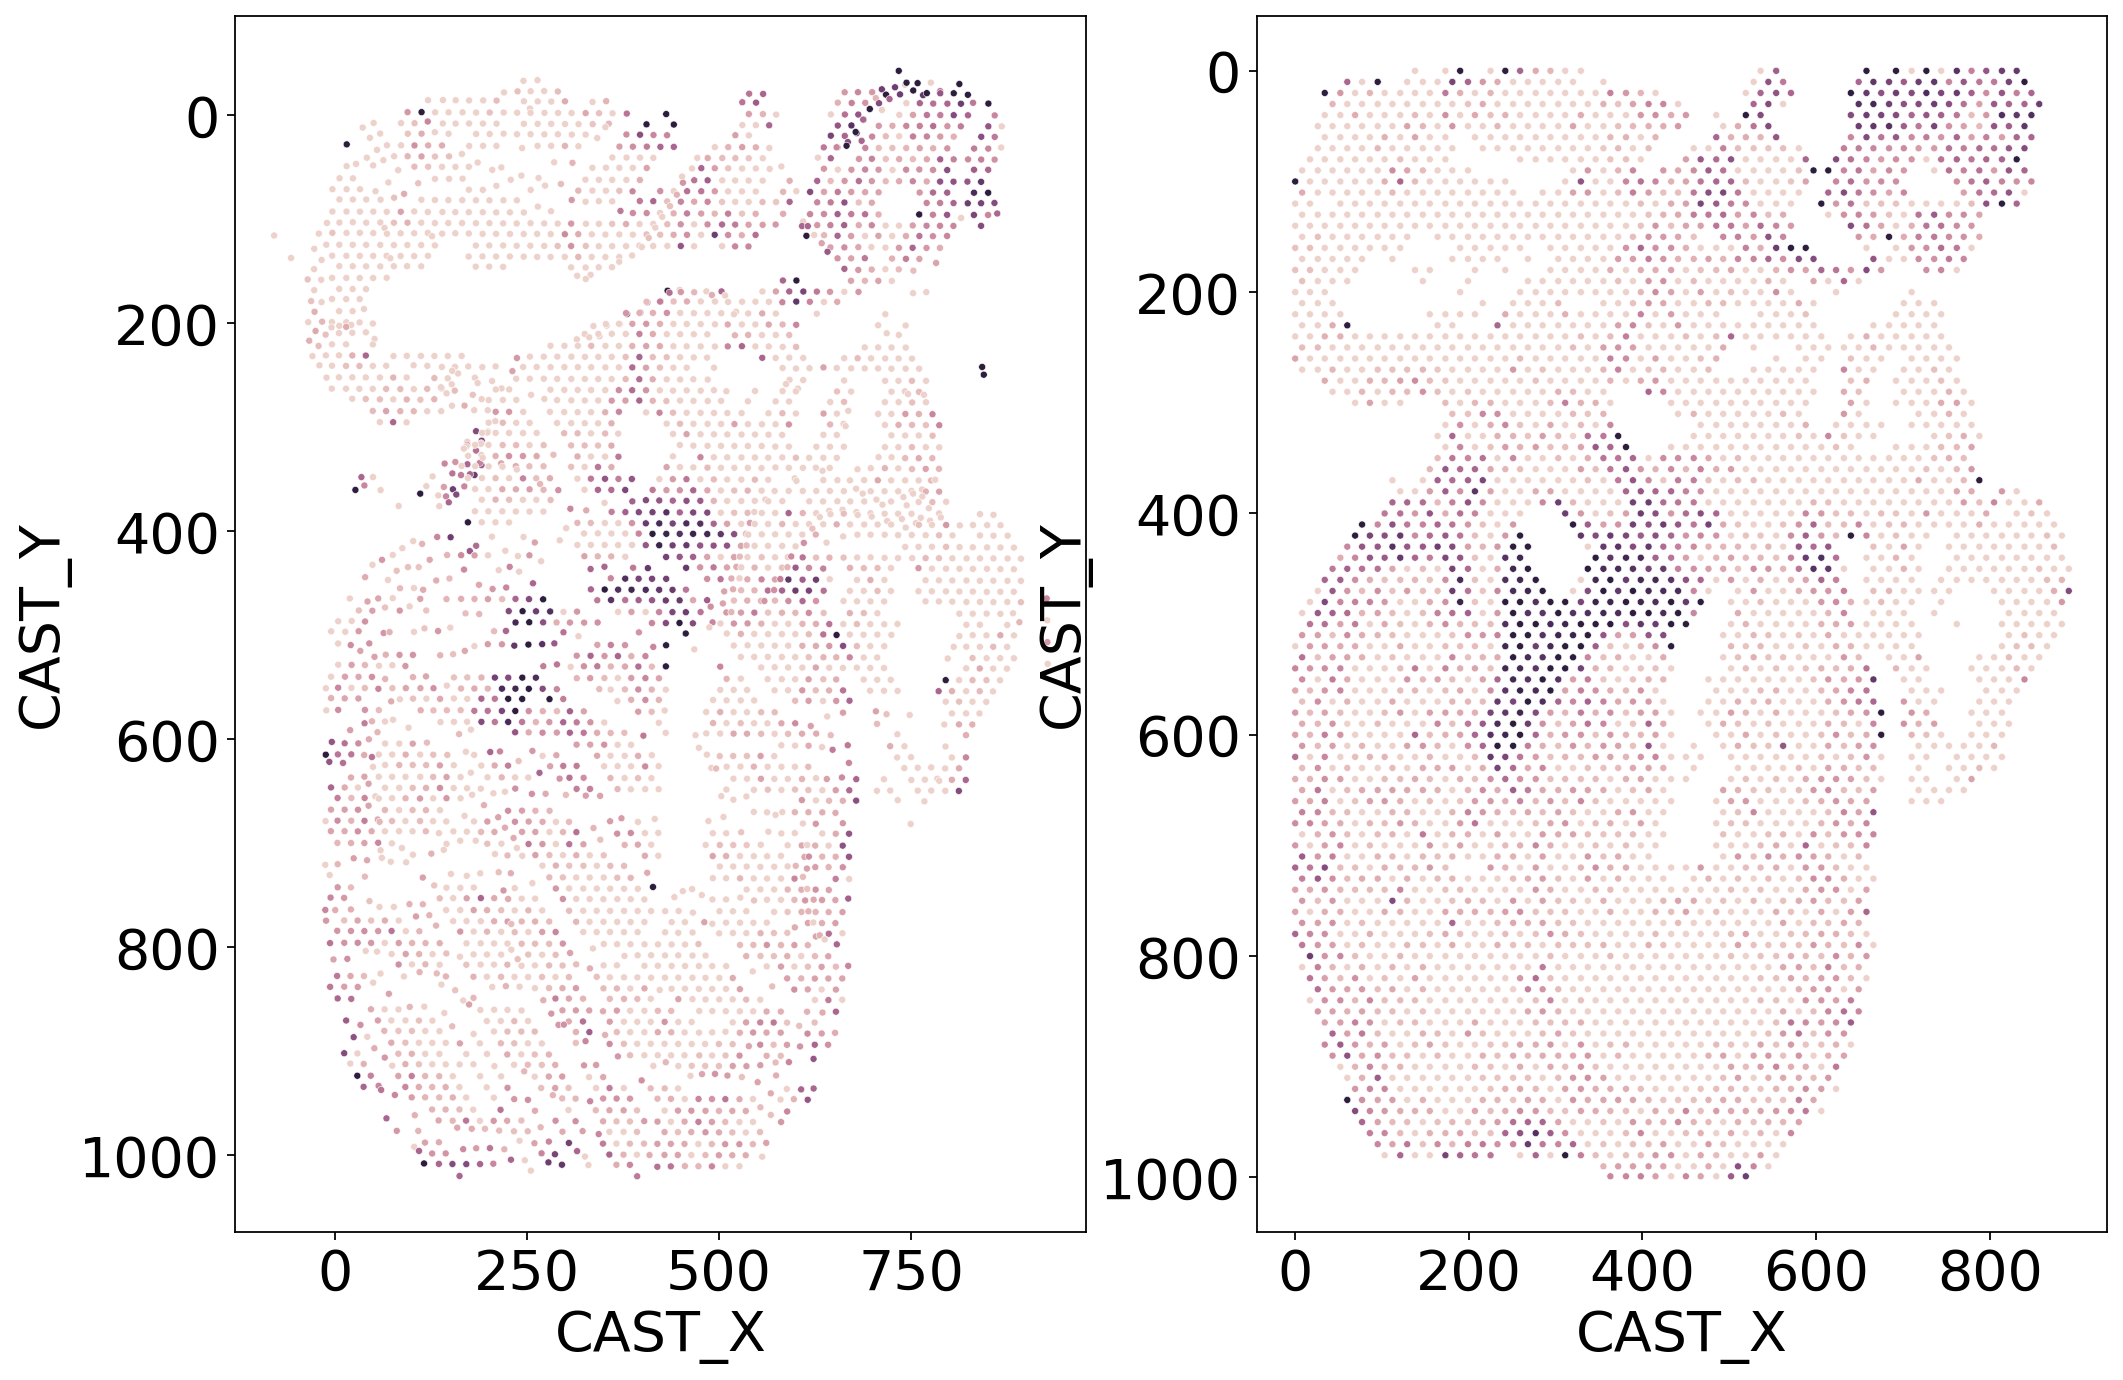

In [151]:
import seaborn as sns
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1,2,figsize=(15,10))
sns.scatterplot(x='CAST_X', y='CAST_Y',hue='Fibroblast_percentage', s=10,data=queryAD.obs, legend=False,ax=ax[0])
ax[0].invert_yaxis()
sns.scatterplot(x='CAST_X', y='CAST_Y',hue='Fibroblast_percentage', s=10,data=refAD.obs, legend=False,ax=ax[1])
ax[1].invert_yaxis()





In [152]:
cols = [
    'Smooth muscle cells_percentage',
    'Fibroblast_percentage',
    'Atrial cardiomyocytes_percentage',
    'Cardiomyocytes_percentage',
    'Endothelium_percentage',
    'Epicardium_percentage',
    'Schwan progenitors_percentage',
    'Ventricular cardiomyocytes_percentage'
]
# Remove '_percentage' to get cell type names
cell_types = [col.replace('_percentage', '') for col in cols]

# Find the column with the maximum value for each row and assign as 'Ground Truth'
queryAD.obs['CellType'] = queryAD.obs[cols].idxmax(axis=1).str.replace('_percentage', '').astype('category')
refAD.obs['CellType'] = refAD.obs[cols].idxmax(axis=1).str.replace('_percentage', '').astype('category')

In [153]:
import numpy as np
from scipy.spatial import cKDTree

# Get coordinates from refAD and queryAD using the CAST-aligned coordinates
ref_coords = refAD.obs[['CAST_X', 'CAST_Y']].values
query_coords = queryAD.obs[['CAST_X', 'CAST_Y']].values

# Get cell types
ref_celltypes = refAD.obs['CellType'].values
query_celltypes = queryAD.obs['CellType'].values

# For each query cell, find the nearest ref cell and compare CellType
tree = cKDTree(ref_coords)
dists, idxs = tree.query(query_coords, k=1)

# Compare cell types
matches = query_celltypes == ref_celltypes[idxs]

# Optionally, print or summarize the results
print(f"Number of matches: {np.sum(matches)} / {len(matches)}")
print(f"Match percentage: {np.mean(matches)*100:.2f}%")

# If you want to see which ones matched/mismatched:
queryAD.obs['NearestRefCellType_CAST'] = ref_celltypes[idxs]
queryAD.obs['CellTypeMatch_CAST'] = matches


Number of matches: 1715 / 3184
Match percentage: 53.86%


In [70]:
ref_coords.max()

1862.7866666666666

In [17]:
cell_types

['Smooth muscle cells',
 'Fibroblast',
 'Atrial cardiomyocytes',
 'Cardiomyocytes',
 'Endothelium',
 'Epicardium',
 'Schwan progenitors',
 'Ventricular cardiomyocytes']

In [85]:
graph_list = {'alignment':['query','ref']}

In [86]:
output_path

'heart_output'

In [87]:
refAD.obs['sample'] = 'ref'
queryAD.obs['sample'] = 'query'

In [88]:
refAD.layers['log1p_norm_scaled'] = ref_matrix
queryAD.layers['log1p_norm_scaled'] = query_matrix

In [89]:
sdata = sc.concat([refAD,queryAD],axis=0)
batch_key = 'sample'
sdata

AnnData object with n_obs × n_vars = 6985 × 67
    obs: 'spot_x', 'spot_y', 'cell_count', 'Endothelium_percentage', 'Atrial cardiomyocytes_percentage', 'Cardiomyocytes_percentage', 'Epicardium_percentage', 'Fibroblast_percentage', 'Schwan progenitors_percentage', 'Smooth muscle cells_percentage', 'Ventricular cardiomyocytes_percentage', 'Cell_Num', 'New_X', 'New_Y', 'CAST_X', 'CAST_Y', 'CellType', 'sample'
    obsm: 'X_spatial', 'spatial'
    layers: 'log1p_norm_scaled'

In [90]:
sdata.layers['raw'] = sdata.X


In [91]:
sdata.var['highly_variable'] = True
sdata.var

,highly_variable
FAM46C,True
TRIL,True
PAM,True
ITLN1,True
LUM,True
...,...
RSPO3,True
ISL1,True
FBLN5,True
COL3A1,True


Start the alignment samples:
Running PCA based on the layer log1p_norm_scaled:


2025-08-26 11:04:13,712 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...


Running Harmony integration:


2025-08-26 11:04:16,570 - harmonypy - INFO - sklearn.KMeans initialization complete.
2025-08-26 11:04:16,597 - harmonypy - INFO - Iteration 1 of 10
2025-08-26 11:04:18,854 - harmonypy - INFO - Iteration 2 of 10
2025-08-26 11:04:20,931 - harmonypy - INFO - Iteration 3 of 10
2025-08-26 11:04:24,065 - harmonypy - INFO - Iteration 4 of 10
2025-08-26 11:04:25,551 - harmonypy - INFO - Iteration 5 of 10
2025-08-26 11:04:26,406 - harmonypy - INFO - Iteration 6 of 10
2025-08-26 11:04:27,141 - harmonypy - INFO - Converged after 6 iterations


Compute a neighborhood graph based on the 50 `n_neighbors`, 30 `n_pcs`:
Generate the UMAP based on the 0.01 `min_dist`, 5 `spread`:


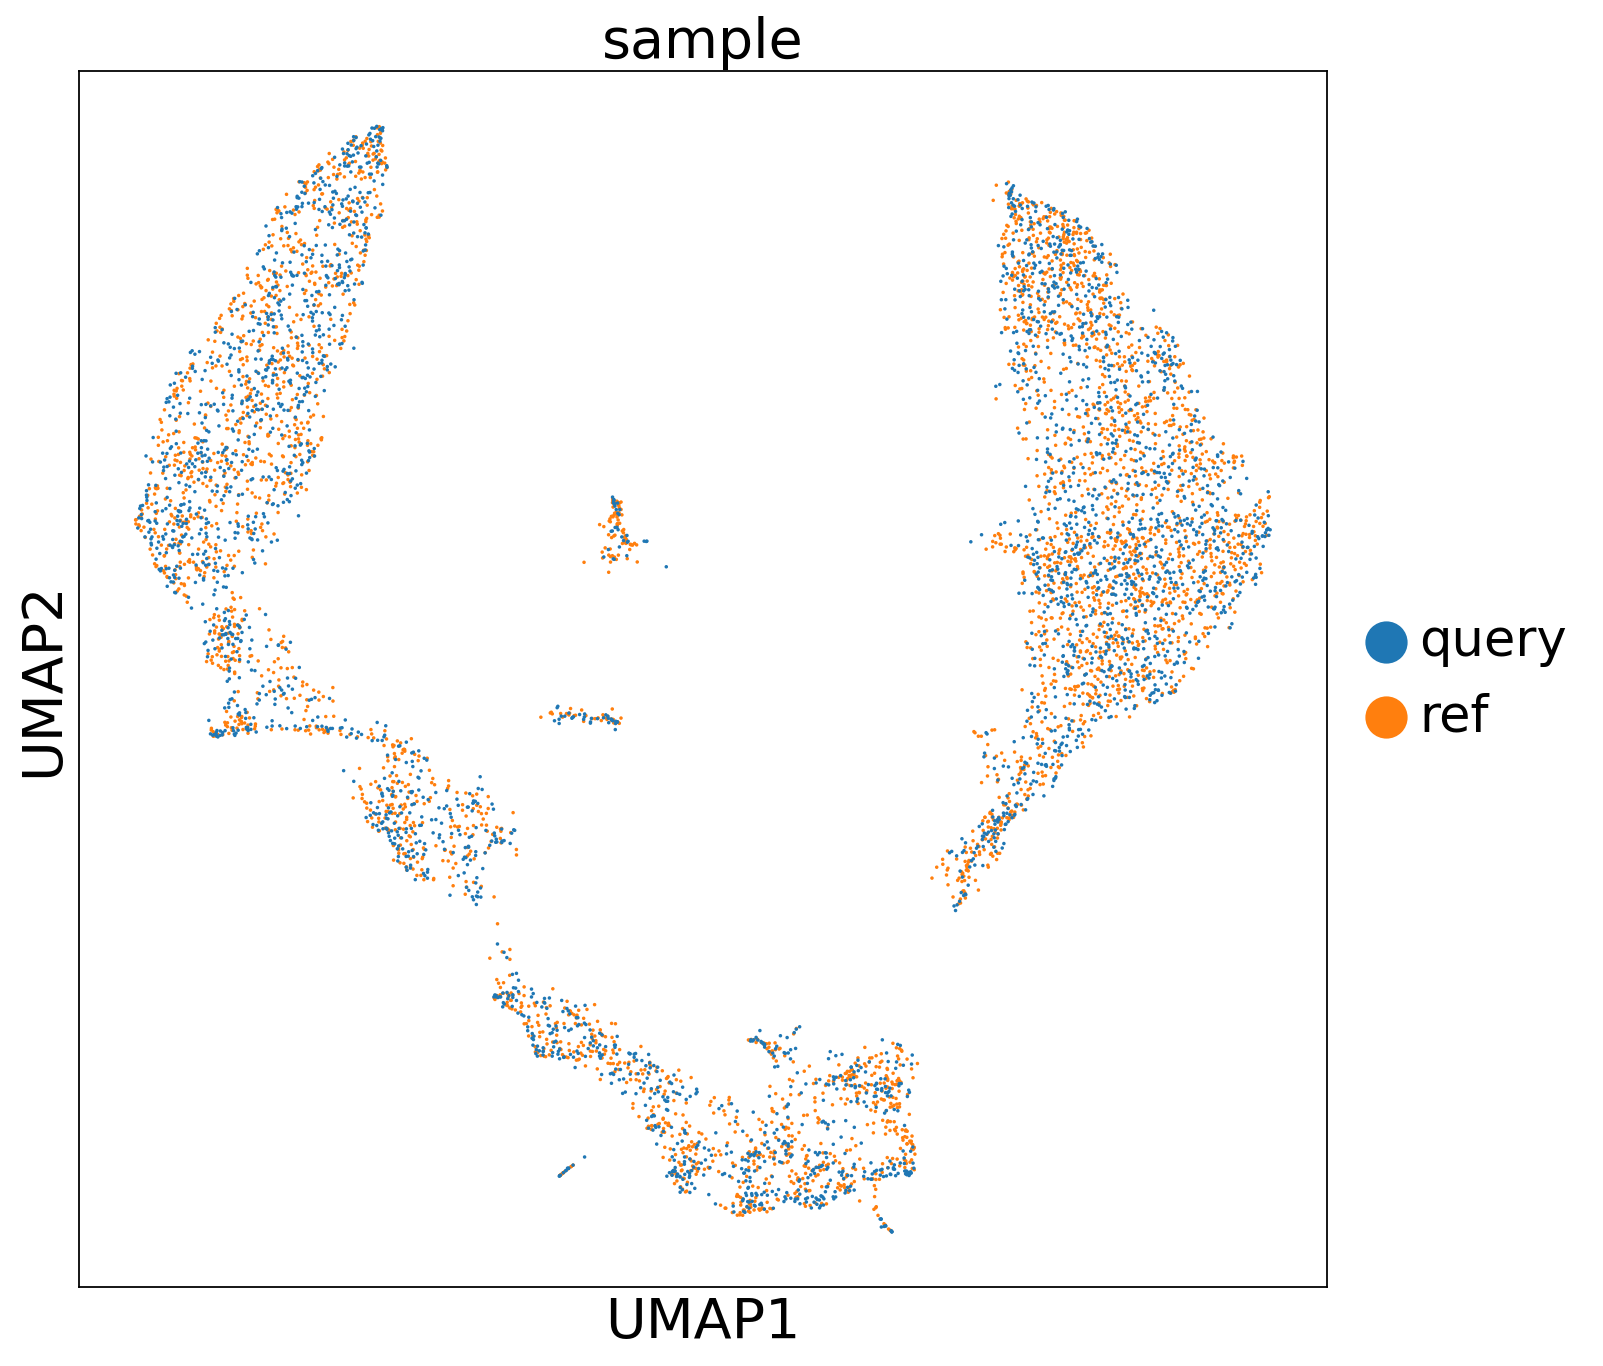

Using cosine distance to calculate cell low dimensional distance:


1it [00:00,  1.93it/s]


Generate evaluation plots:


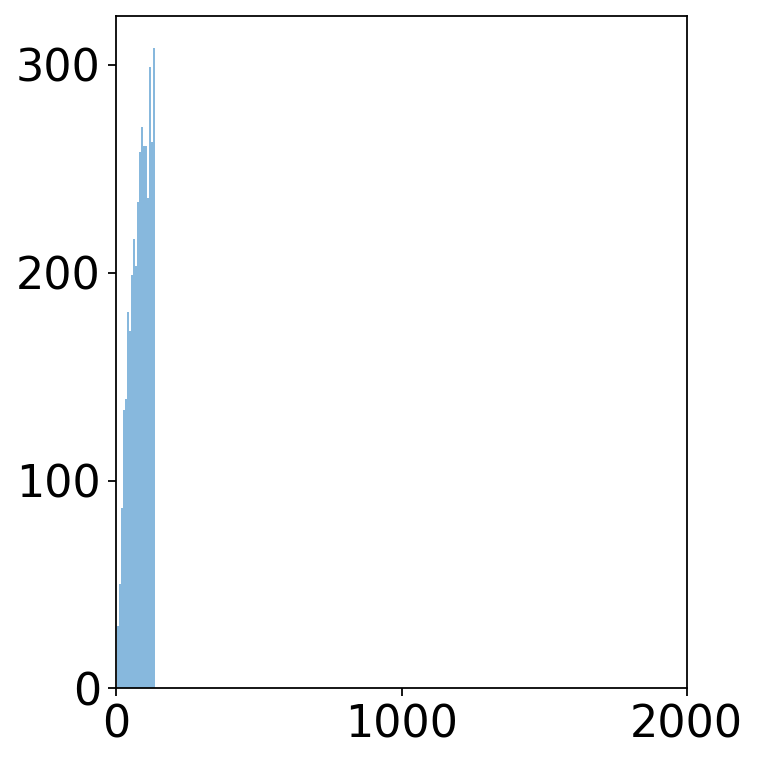

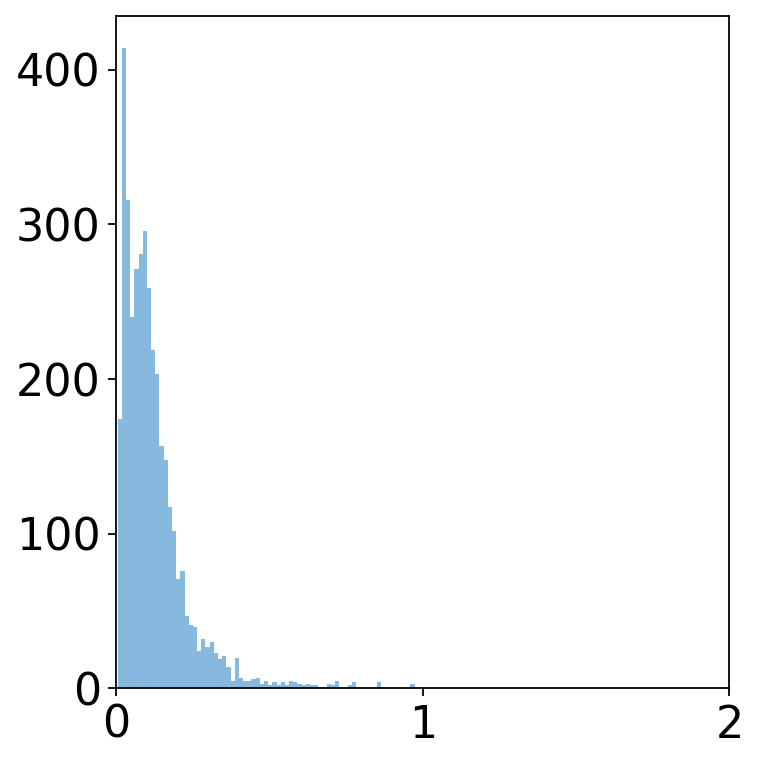

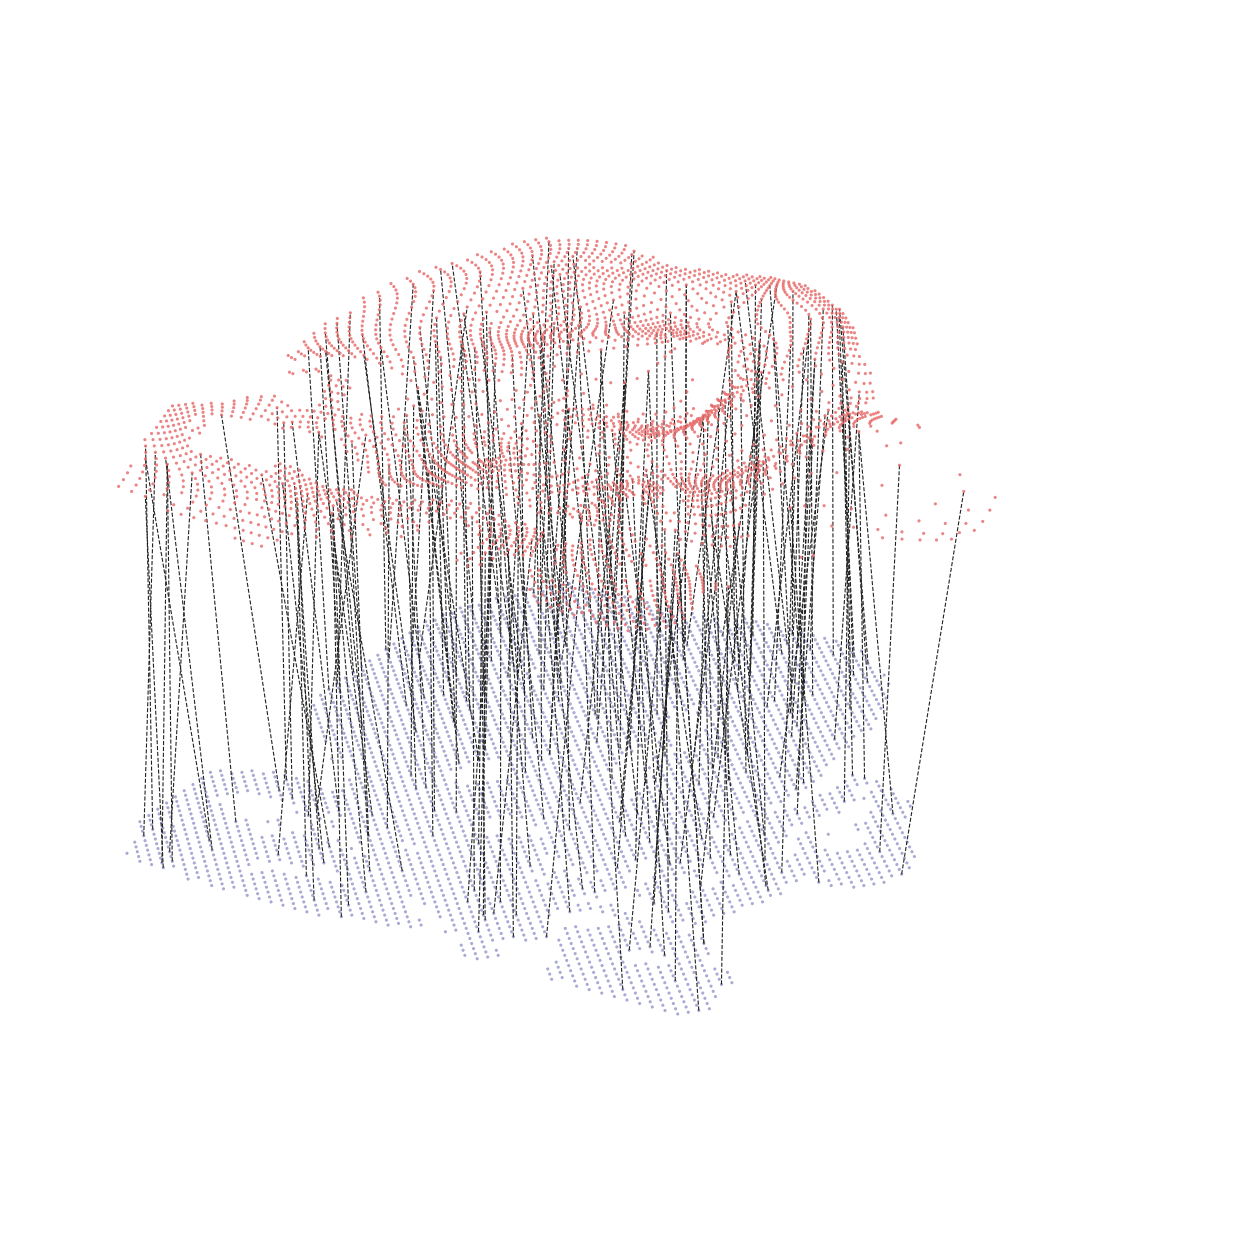

In [104]:
sdata_refs = {}
list_ts = {}
color_dict = {
        'Smooth muscle cells': '#256b00',
        'Fibroblast': '#ee750a',
        'Atrial cardiomyocytes': '#f280cf',
        'Cardiomyocytes': '#f24f4b',
        'Endothelium': '#e8e879',
        'Epicardium': '#a8e1eb',
        'Schwan progenitors': '#395ba8',
        'Ventricular cardiomyocytes': '#697491',    }
for rep in graph_list.keys():
    print(f'Start the {rep} samples:')
    source_sample, target_sample = graph_list[rep]
    output_path_t = f'{output_path}/{source_sample}_to_{target_sample}'
    os.makedirs(output_path_t,exist_ok=True)
    sdata_refs[rep],list_ts[rep] = CAST.CAST_PROJECT(
        sdata_inte = sdata[np.isin(sdata.obs[batch_key],[source_sample, target_sample])], # the integrated dataset
        source_sample = source_sample, # the source sample name
        target_sample = target_sample, # the target sample name
        coords_source = np.array(sdata[np.isin(sdata.obs[batch_key],source_sample),:].obs.loc[:,['CAST_X','CAST_Y']]), # the coordinates of the source sample
        coords_target = np.array(sdata[np.isin(sdata.obs[batch_key],target_sample),:].obs.loc[:,['CAST_X','CAST_Y']]), # the coordinates of the target sample
        scaled_layer = 'log1p_norm_scaled', # the scaled layer name in `adata.layers`, which is used to be integrated
        batch_key = batch_key, # the column name of the samples in `obs`
        source_sample_ctype_col = None, # the column name of the cell type in `obs`
        output_path = output_path_t, # the output path
        integration_strategy = 'Harmony', # 'Harmony' or None (use existing integrated features)
        color_dict = color_dict # the color dict for the cell type
    )

In [110]:
sdata[np.isin(sdata.obs[batch_key],[source_sample, target_sample])]

View of AnnData object with n_obs × n_vars = 6985 × 67
    obs: 'spot_x', 'spot_y', 'cell_count', 'Endothelium_percentage', 'Atrial cardiomyocytes_percentage', 'Cardiomyocytes_percentage', 'Epicardium_percentage', 'Fibroblast_percentage', 'Schwan progenitors_percentage', 'Smooth muscle cells_percentage', 'Ventricular cardiomyocytes_percentage', 'Cell_Num', 'New_X', 'New_Y', 'CAST_X', 'CAST_Y', 'CellType', 'sample'
    var: 'highly_variable'
    obsm: 'X_spatial', 'spatial'
    layers: 'log1p_norm_scaled', 'raw'

<Axes: title={'center': 'CellType'}, xlabel='spatial1', ylabel='spatial2'>

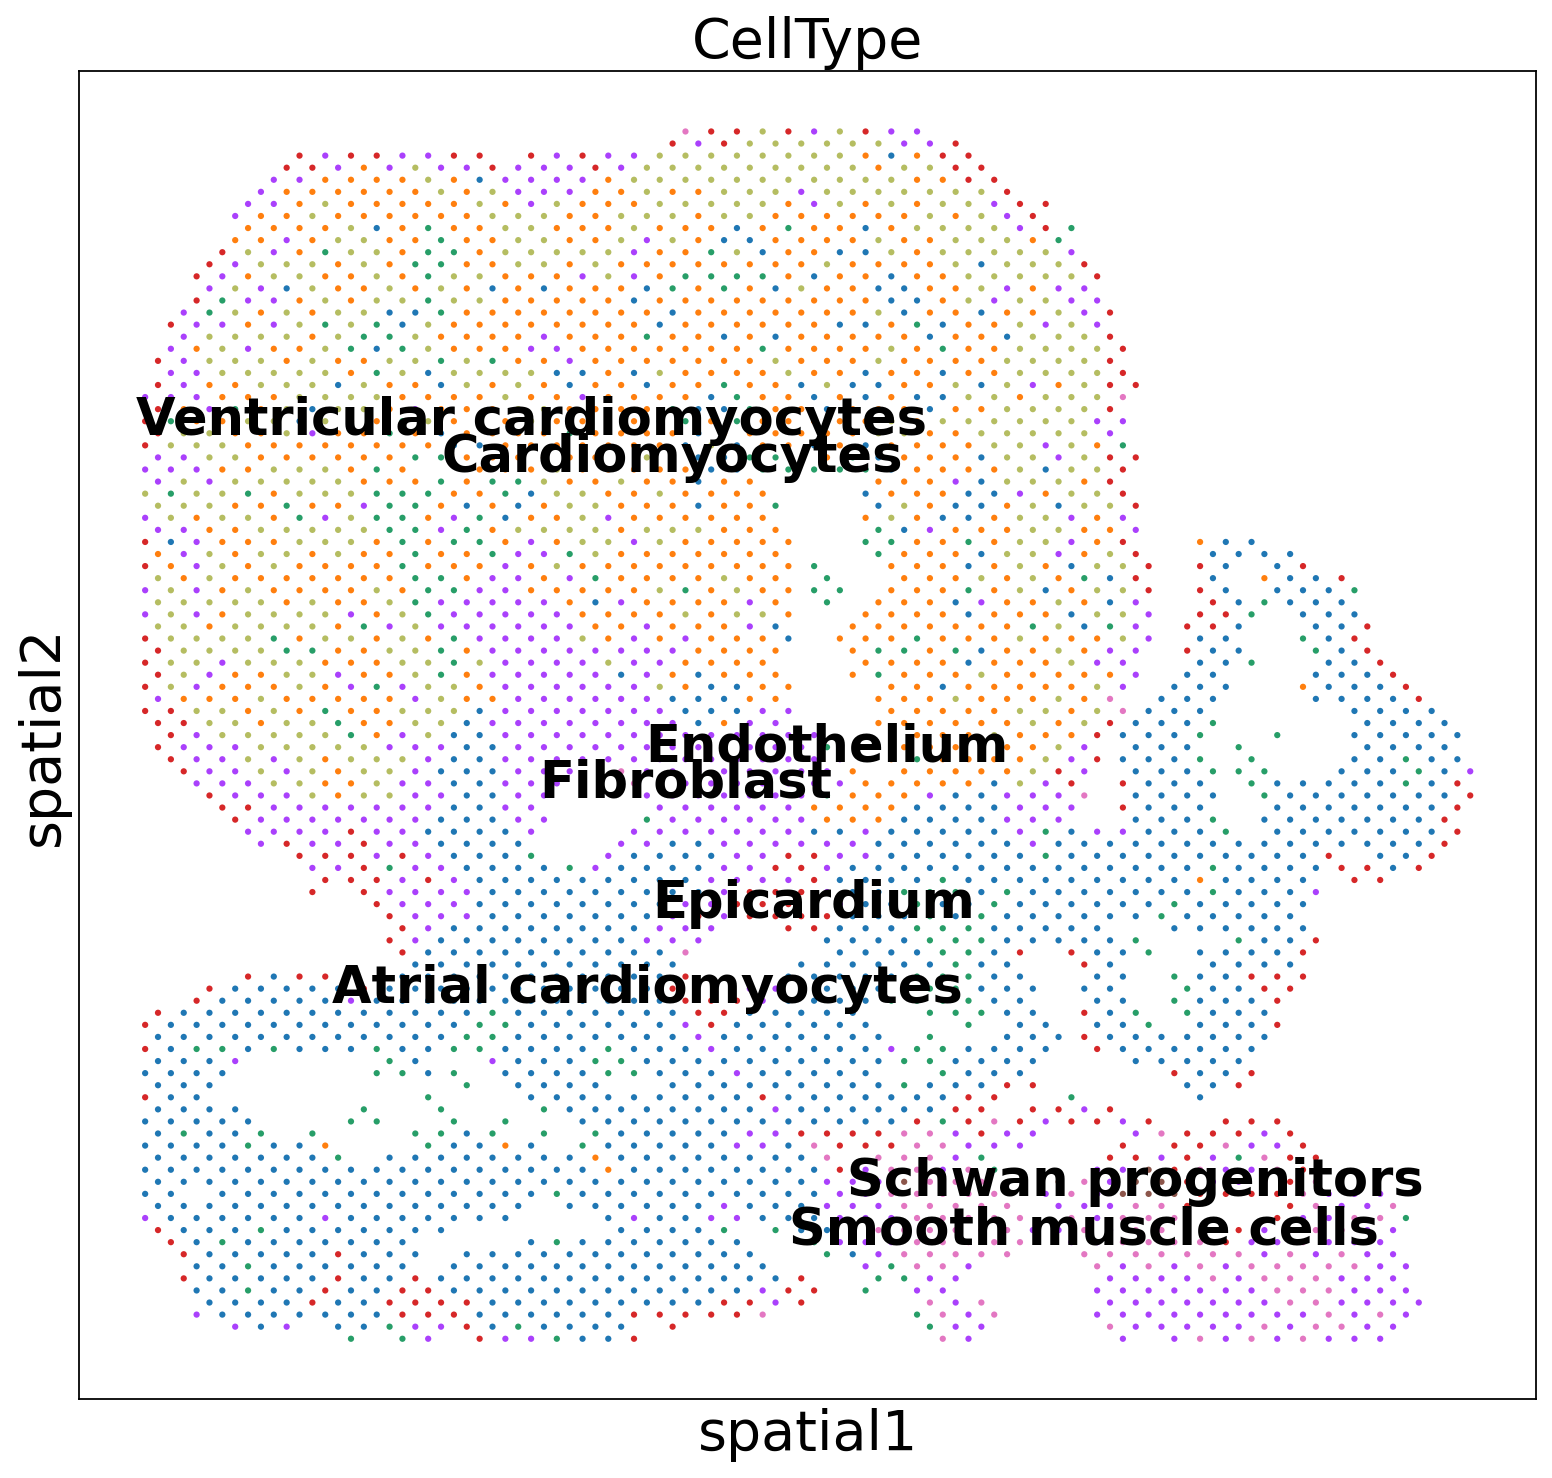

In [108]:
sc.pl.scatter(sdata_refs['alignment'],basis='spatial',color='CellType',legend_loc='on data',show=False)

In [94]:
len(queryAD.obs), len(refAD.obs), len(sdata)

(3184, 3801, 6985)

In [95]:
len(np.unique(list_ts['alignment'][0][:,0]))

1669

In [98]:
y_ref = sdata_refs['alignment'].obs['CellType'].values
y_query = queryAD.obs.iloc[list_ts['alignment'][0][:,0]].CellType.values
accuracy = (y_ref == y_query).mean()
print("Accuracy:", accuracy)


Accuracy: 0.6848197842672981


In [111]:
import pandas as pd
refAD = sc.read_h5ad("rep2_spot.h5ad")
queryAD = sc.read_h5ad("rep1_spot.h5ad")
refDF = pd.read_csv("valis_output/ref_cell_positions.csv")
queryDF = pd.read_csv("valis_output/moving_valisOutput.csv")
refDF.index = refDF.Cell_Num.astype(str)
queryDF.index = queryDF.Cell_Num.astype(str)
print(refAD.obs.shape, queryAD.obs.shape, refDF.shape, queryDF.shape)
refAD.obs['New_X'] = refDF.loc[refAD.obs.Cell_Num.astype(str),'New_X']
refAD.obs['New_Y'] = refDF.loc[refAD.obs.Cell_Num.astype(str),'New_Y']

queryAD.obs['New_X'] = queryDF.loc[queryAD.obs.Cell_Num.astype(str),'Valis_X']
queryAD.obs['New_Y'] = queryDF.loc[queryAD.obs.Cell_Num.astype(str),'Valis_Y']





(3801, 12) (3184, 12) (3801, 7) (3184, 10)


In [116]:
queryAD.var.sample(10).index

Index(['RSPO3', 'CLDN5', 'PAM', 'STMN2', 'MYOZ2', 'MYOM1', 'NOV', 'FOXS1',
       'SORBS2', 'PLN'],
      dtype='object')

,barcodes,xcoord,ycoord
0,0,138.0,0.0
1,1,173.0,0.0
2,2,190.0,0.0
3,3,225.0,0.0
4,4,242.0,0.0
...,...,...,...
3796,3796,450.0,999.0
3797,3797,467.0,999.0
3798,3798,485.0,999.0
3799,3799,502.0,999.0


In [124]:
outDF = refAD.obs[['New_X','New_Y']]
outDF.reset_index(inplace=True, drop=False)
outDF.columns = ['barcodes', 'xcoord', 'ycoord']

outDF.to_csv('STIM_inputs/ref_cell_positions.csv',index=False)
pd.DataFrame(refAD.X, index=outDF.barcodes.values, columns=refAD.var.index).T.to_csv('STIM_inputs/ref_expression.csv',index=True)


outDF = queryAD.obs[['New_X','New_Y']]
outDF.reset_index(inplace=True, drop=False)
outDF.columns = ['barcodes', 'xcoord', 'ycoord']
outDF.to_csv('STIM_inputs/query_cell_positions.csv',index=False)
pd.DataFrame(queryAD.X, index=outDF.barcodes.values, columns=queryAD.var.index).T.to_csv('STIM_inputs/query_expression.csv',index=True)


In [125]:
outDF

,barcodes,xcoord,ycoord
0,0,657.516956,-0.133918
1,1,674.407621,-0.263716
2,2,692.380183,-0.377012
3,3,704.671579,-2.997449
4,4,726.064387,-19.761782
...,...,...,...
3179,3179,458.896835,969.977380
3180,3180,476.132349,970.059007
3181,3181,493.182212,970.083014
3182,3182,510.231735,969.973623
